In [1]:
!pip install -q kaggle ultralytics

In [2]:
from getpass import getpass

KAGGLE_API_TOKEN = getpass("Enter your Kaggle API token: ")

Enter your Kaggle API token: ··········


In [3]:
import os

os.environ["KAGGLE_API_TOKEN"] = KAGGLE_API_TOKEN

In [4]:
!kaggle datasets list -s waste-classification-data

ref                                                                   title                                                   size  lastUpdated                 downloadCount  voteCount  usabilityRating  
--------------------------------------------------------------------  ------------------------------------------------  ----------  --------------------------  -------------  ---------  ---------------  
techsash/waste-classification-data                                    Waste Classification data                          447914276  2019-06-16 03:24:52.733000          61426        609  0.875            
sapal6/waste-classification-data-v2                                   Waste Classification Data v2                       236799849  2019-11-29 03:47:08.897000           3146         35  0.5625           
joebeachcapital/realwaste                                             RealWaste Image Classification                     688660611  2024-01-19 03:47:23.723000           7228         51

In [5]:
!kaggle datasets download -d techsash/waste-classification-data -p /content

Dataset URL: https://www.kaggle.com/datasets/techsash/waste-classification-data
License(s): CC-BY-SA-4.0
waste-classification-data.zip: Skipping, found more recently modified local copy (use --force to force download)


In [6]:
!ls -lh /content

total 428M
drwxr-xr-x 1 root root 4.0K Aug 24 13:28 sample_data
-rw-r--r-- 1 root root 428M Oct 25  2019 waste-classification-data.zip
drwxr-xr-x 4 root root 4.0K Sep  4 14:03 waste_dataset
drwxr-xr-x 5 root root 4.0K Sep  4 14:03 yolo_waste


In [7]:
import zipfile
import os

zip_path = "/content/waste-classification-data.zip"
extract_path = "/content/waste_dataset"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [8]:
for root, dirs, files in os.walk("/content/waste_dataset"):
    level = root.replace("/content/waste_dataset", "").count(os.sep)

    if level <= 4:
        print(root)

/content/waste_dataset
/content/waste_dataset/DATASET
/content/waste_dataset/DATASET/TRAIN
/content/waste_dataset/DATASET/TRAIN/R
/content/waste_dataset/DATASET/TRAIN/O
/content/waste_dataset/DATASET/TEST
/content/waste_dataset/DATASET/TEST/R
/content/waste_dataset/DATASET/TEST/O
/content/waste_dataset/dataset
/content/waste_dataset/dataset/DATASET
/content/waste_dataset/dataset/DATASET/TRAIN
/content/waste_dataset/dataset/DATASET/TRAIN/R
/content/waste_dataset/dataset/DATASET/TRAIN/O
/content/waste_dataset/dataset/DATASET/TEST
/content/waste_dataset/dataset/DATASET/TEST/R
/content/waste_dataset/dataset/DATASET/TEST/O


In [9]:
import os

train_dir = None
test_dir = None

for root, dirs, files in os.walk("/content/waste_dataset"):

    if os.path.basename(root) == "TRAIN":
        if "O" in dirs and "R" in dirs:
            train_dir = root

    if os.path.basename(root) == "TEST":
        if "O" in dirs and "R" in dirs:
            test_dir = root

print("TRAIN:", train_dir)
print("TEST :", test_dir)

TRAIN: /content/waste_dataset/dataset/DATASET/TRAIN
TEST : /content/waste_dataset/dataset/DATASET/TEST


In [10]:
train_O = os.path.join(train_dir, "O")
train_R = os.path.join(train_dir, "R")

test_O = os.path.join(test_dir, "O")
test_R = os.path.join(test_dir, "R")

print("TRAIN")
print("Organic     :", len(os.listdir(train_O)))
print("Recyclable  :", len(os.listdir(train_R)))

print("\nTEST")
print("Organic     :", len(os.listdir(test_O)))
print("Recyclable  :", len(os.listdir(test_R)))

TRAIN
Organic     : 12565
Recyclable  : 9999

TEST
Organic     : 1401
Recyclable  : 1112


In [11]:
import os

new_dataset = "/content/yolo_waste"

folders = [
    "train/BIODEGRADABLE",
    "train/NON_BIODEGRADABLE",
    "val/BIODEGRADABLE",
    "val/NON_BIODEGRADABLE",
    "test/BIODEGRADABLE",
    "test/NON_BIODEGRADABLE"
]

for folder in folders:
    os.makedirs(
        os.path.join(new_dataset, folder),
        exist_ok=True
    )

print("Directories created!")

Directories created!


In [12]:
import random
import shutil

random.seed(42)

def split_and_copy(source, train_dest, val_dest, val_ratio=0.2):

    files = [
        f for f in os.listdir(source)
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png")
        )
    ]

    random.shuffle(files)

    split_index = int(len(files) * (1 - val_ratio))

    train_files = files[:split_index]
    val_files = files[split_index:]

    for f in train_files:
        shutil.copy2(
            os.path.join(source, f),
            os.path.join(train_dest, f)
        )

    for f in val_files:
        shutil.copy2(
            os.path.join(source, f),
            os.path.join(val_dest, f)
        )

    return len(train_files), len(val_files)

In [13]:
train_count_O, val_count_O = split_and_copy(
    train_O,
    "/content/yolo_waste/train/BIODEGRADABLE",
    "/content/yolo_waste/val/BIODEGRADABLE"
)

In [14]:
train_count_R, val_count_R = split_and_copy(
    train_R,
    "/content/yolo_waste/train/NON_BIODEGRADABLE",
    "/content/yolo_waste/val/NON_BIODEGRADABLE"
)

In [15]:
def copy_all(source, destination):

    files = [
        f for f in os.listdir(source)
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png")
        )
    ]

    for f in files:

        shutil.copy2(
            os.path.join(source, f),
            os.path.join(destination, f)
        )

    return len(files)

In [16]:
test_count_O = copy_all(
    test_O,
    "/content/yolo_waste/test/BIODEGRADABLE"
)

In [17]:
test_count_R = copy_all(
    test_R,
    "/content/yolo_waste/test/NON_BIODEGRADABLE"
)

In [18]:
for root, dirs, files in os.walk("/content/yolo_waste"):

    level = root.replace("/content/yolo_waste", "").count(os.sep)

    if level <= 2:
        print(root, "->", len(files), "files")

/content/yolo_waste -> 0 files
/content/yolo_waste/test -> 0 files
/content/yolo_waste/test/NON_BIODEGRADABLE -> 1112 files
/content/yolo_waste/test/BIODEGRADABLE -> 1401 files
/content/yolo_waste/train -> 0 files
/content/yolo_waste/train/NON_BIODEGRADABLE -> 7999 files
/content/yolo_waste/train/BIODEGRADABLE -> 10052 files
/content/yolo_waste/val -> 0 files
/content/yolo_waste/val/NON_BIODEGRADABLE -> 2000 files
/content/yolo_waste/val/BIODEGRADABLE -> 2513 files


In [19]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: Tesla T4


In [20]:
from ultralytics import YOLO
model = YOLO("yolov8n-cls.pt")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.


In [21]:
results = model.train(
    data="/content/yolo_waste",
    epochs=15,
    imgsz=224,
    batch=32,
    patience=10,
    project="/content/waste_yolo",
    name="yolov8n_classification"
)

Ultralytics 8.4.138 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_waste, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=15, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_classification, nbs=64, nms=Fal

In [22]:
import os

weights_dir = "/content/waste_yolo/yolov8n_classification/weights"

print(os.listdir(weights_dir))

['best.pt', 'last.pt']


In [23]:
best_model = YOLO(
    "/content/waste_yolo/yolov8n_classification/weights/best.pt"
)

In [24]:
metrics = best_model.val(
    data="/content/yolo_waste"
)

print(metrics)

Ultralytics 8.4.138 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n-cls summary (fused): 30 layers, 1,437,442 parameters, 0 gradients, 3.3 GFLOPs
train: /content/yolo_waste/train... found 18051 images in 2 classes ✅ 
val: /content/yolo_waste/val... found 4513 images in 2 classes ✅ 
test: /content/yolo_waste/test... found 2513 images in 2 classes ✅ 
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 257.6±134.1 MB/s, size: 8.5 KB)
val: Scanning /content/yolo_waste/val... 4513 images, 0 corrupt: 100% ━━━━━━━━━━━━ 4513/4513 996.3Mit/s 0.0s
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 283/283 16.6it/s 17.0s
                   all      0.957          1
Speed: 0.1ms preprocess, 1.0ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to /content/runs/classify/val
ultralytics.utils.metrics.ClassifyMetrics object with attributes:

confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7e7f79cc3b90>
curves: []
curves_resu

In [25]:
print("Top-1 Accuracy:", metrics.top1)
print("Top-5 Accuracy:", metrics.top5)

Top-1 Accuracy: 0.9567915201187134
Top-5 Accuracy: 1.0


In [28]:
import glob

test_images = glob.glob(
    "/content/yolo_waste/test/*/*"
)

test_images = [
    x for x in test_images
    if x.lower().endswith(
        (".jpg", ".jpeg", ".png", ".bmp", ".webp")
    )
]

print("Test images:", len(test_images))

Test images: 2513


In [31]:
import os

for root, dirs, files in os.walk("/content/yolo_waste"):
    level = root.replace("/content/yolo_waste", "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")

yolo_waste/
  test/
    NON_BIODEGRADABLE/
    BIODEGRADABLE/
  train/
    NON_BIODEGRADABLE/
    BIODEGRADABLE/
  val/
    NON_BIODEGRADABLE/
    BIODEGRADABLE/


In [32]:
import glob

test_images = glob.glob(
    "/content/yolo_waste/test/*/*.jpg"
)

# Also include png/jpeg if present
test_images += glob.glob(
    "/content/yolo_waste/test/*/*.jpeg"
)

test_images += glob.glob(
    "/content/yolo_waste/test/*/*.png"
)

print("Number of test images:", len(test_images))
print("First 5 images:")
for img in test_images[:5]:
    print(img)

Number of test images: 2513
First 5 images:
/content/yolo_waste/test/NON_BIODEGRADABLE/R_10222.jpg
/content/yolo_waste/test/NON_BIODEGRADABLE/R_10296.jpg
/content/yolo_waste/test/NON_BIODEGRADABLE/R_10948.jpg
/content/yolo_waste/test/NON_BIODEGRADABLE/R_10851.jpg
/content/yolo_waste/test/NON_BIODEGRADABLE/R_10598.jpg


In [33]:
test_results = best_model.predict(
    source=test_images,
    save=True
)

print("Prediction completed!")


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

0: 224x224 BIODEGRADABLE 0.96, NON_BIODEGRADABLE 0.04, 0.2ms
1: 224x224 NON_BIODEGRADABLE 1.00, BIODEGRADABLE 0.00, 0.2ms
2: 224x224 NON_BIODEGRADABLE 0.86, BIODEGRADABLE 0.14, 0.2ms
3: 224x224 NON_BIODEGRADABLE 0.81, BIODEGRADABLE 0.19, 0.2ms
4: 224x224 NON_BIODEGRADABLE 0.99, BIODEGRADABLE 0.01, 0.2ms
5: 224x224 NON_BIODEGRADABLE 1.00, BIODEGRADABLE 0.00, 0.2ms
6: 224x224 NON_BIODEGRADABLE 1.00, BIODEGRADABLE 0.00, 0.2ms
7: 224x224 NON_BIODEGRADABLE 1.0

In [34]:
import os
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Class names in the SAME order as your YOLOv8 model
classes = ["BIODEGRADABLE", "NON_BIODEGRADABLE"]

true_labels = []
pred_labels = []

for image_path, result in zip(test_images, test_results):

    # -----------------------------
    # ACTUAL LABEL
    # -----------------------------
    # Example:
    # /content/yolo_waste/test/BIODEGRADABLE/image.jpg
    parent_folder = os.path.basename(
        os.path.dirname(image_path)
    )

    true_label = classes.index(parent_folder)

    # -----------------------------
    # PREDICTED LABEL
    # -----------------------------
    predicted_label = result.probs.top1

    true_labels.append(true_label)
    pred_labels.append(predicted_label)


# =============================
# CALCULATE METRICS
# =============================

accuracy = accuracy_score(
    true_labels,
    pred_labels
)

precision = precision_score(
    true_labels,
    pred_labels,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    true_labels,
    pred_labels,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    true_labels,
    pred_labels,
    average="weighted",
    zero_division=0
)


# =============================
# PRINT RESULTS
# =============================

print("TEST PERFORMANCE")
print("================")

print(f"Accuracy : {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall   : {recall * 100:.2f}%")
print(f"F1 Score : {f1 * 100:.2f}%")


# =============================
# CLASSIFICATION REPORT
# =============================

print("\nCLASSIFICATION REPORT")
print("=====================")

print(
    classification_report(
        true_labels,
        pred_labels,
        target_names=classes,
        zero_division=0
    )
)


# =============================
# CONFUSION MATRIX
# =============================

cm = confusion_matrix(
    true_labels,
    pred_labels
)

print("\nCONFUSION MATRIX")
print("================")

print(cm)

TEST PERFORMANCE
Accuracy : 90.17%
Precision: 91.09%
Recall   : 90.17%
F1 Score : 90.01%

CLASSIFICATION REPORT
                   precision    recall  f1-score   support

    BIODEGRADABLE       0.86      0.98      0.92      1401
NON_BIODEGRADABLE       0.97      0.80      0.88      1112

         accuracy                           0.90      2513
        macro avg       0.92      0.89      0.90      2513
     weighted avg       0.91      0.90      0.90      2513


CONFUSION MATRIX
[[1378   23]
 [ 224  888]]


In [35]:
print(
    classification_report(
        true_labels,
        pred_labels,
        target_names=classes
    )
)

                   precision    recall  f1-score   support

    BIODEGRADABLE       0.86      0.98      0.92      1401
NON_BIODEGRADABLE       0.97      0.80      0.88      1112

         accuracy                           0.90      2513
        macro avg       0.92      0.89      0.90      2513
     weighted avg       0.91      0.90      0.90      2513



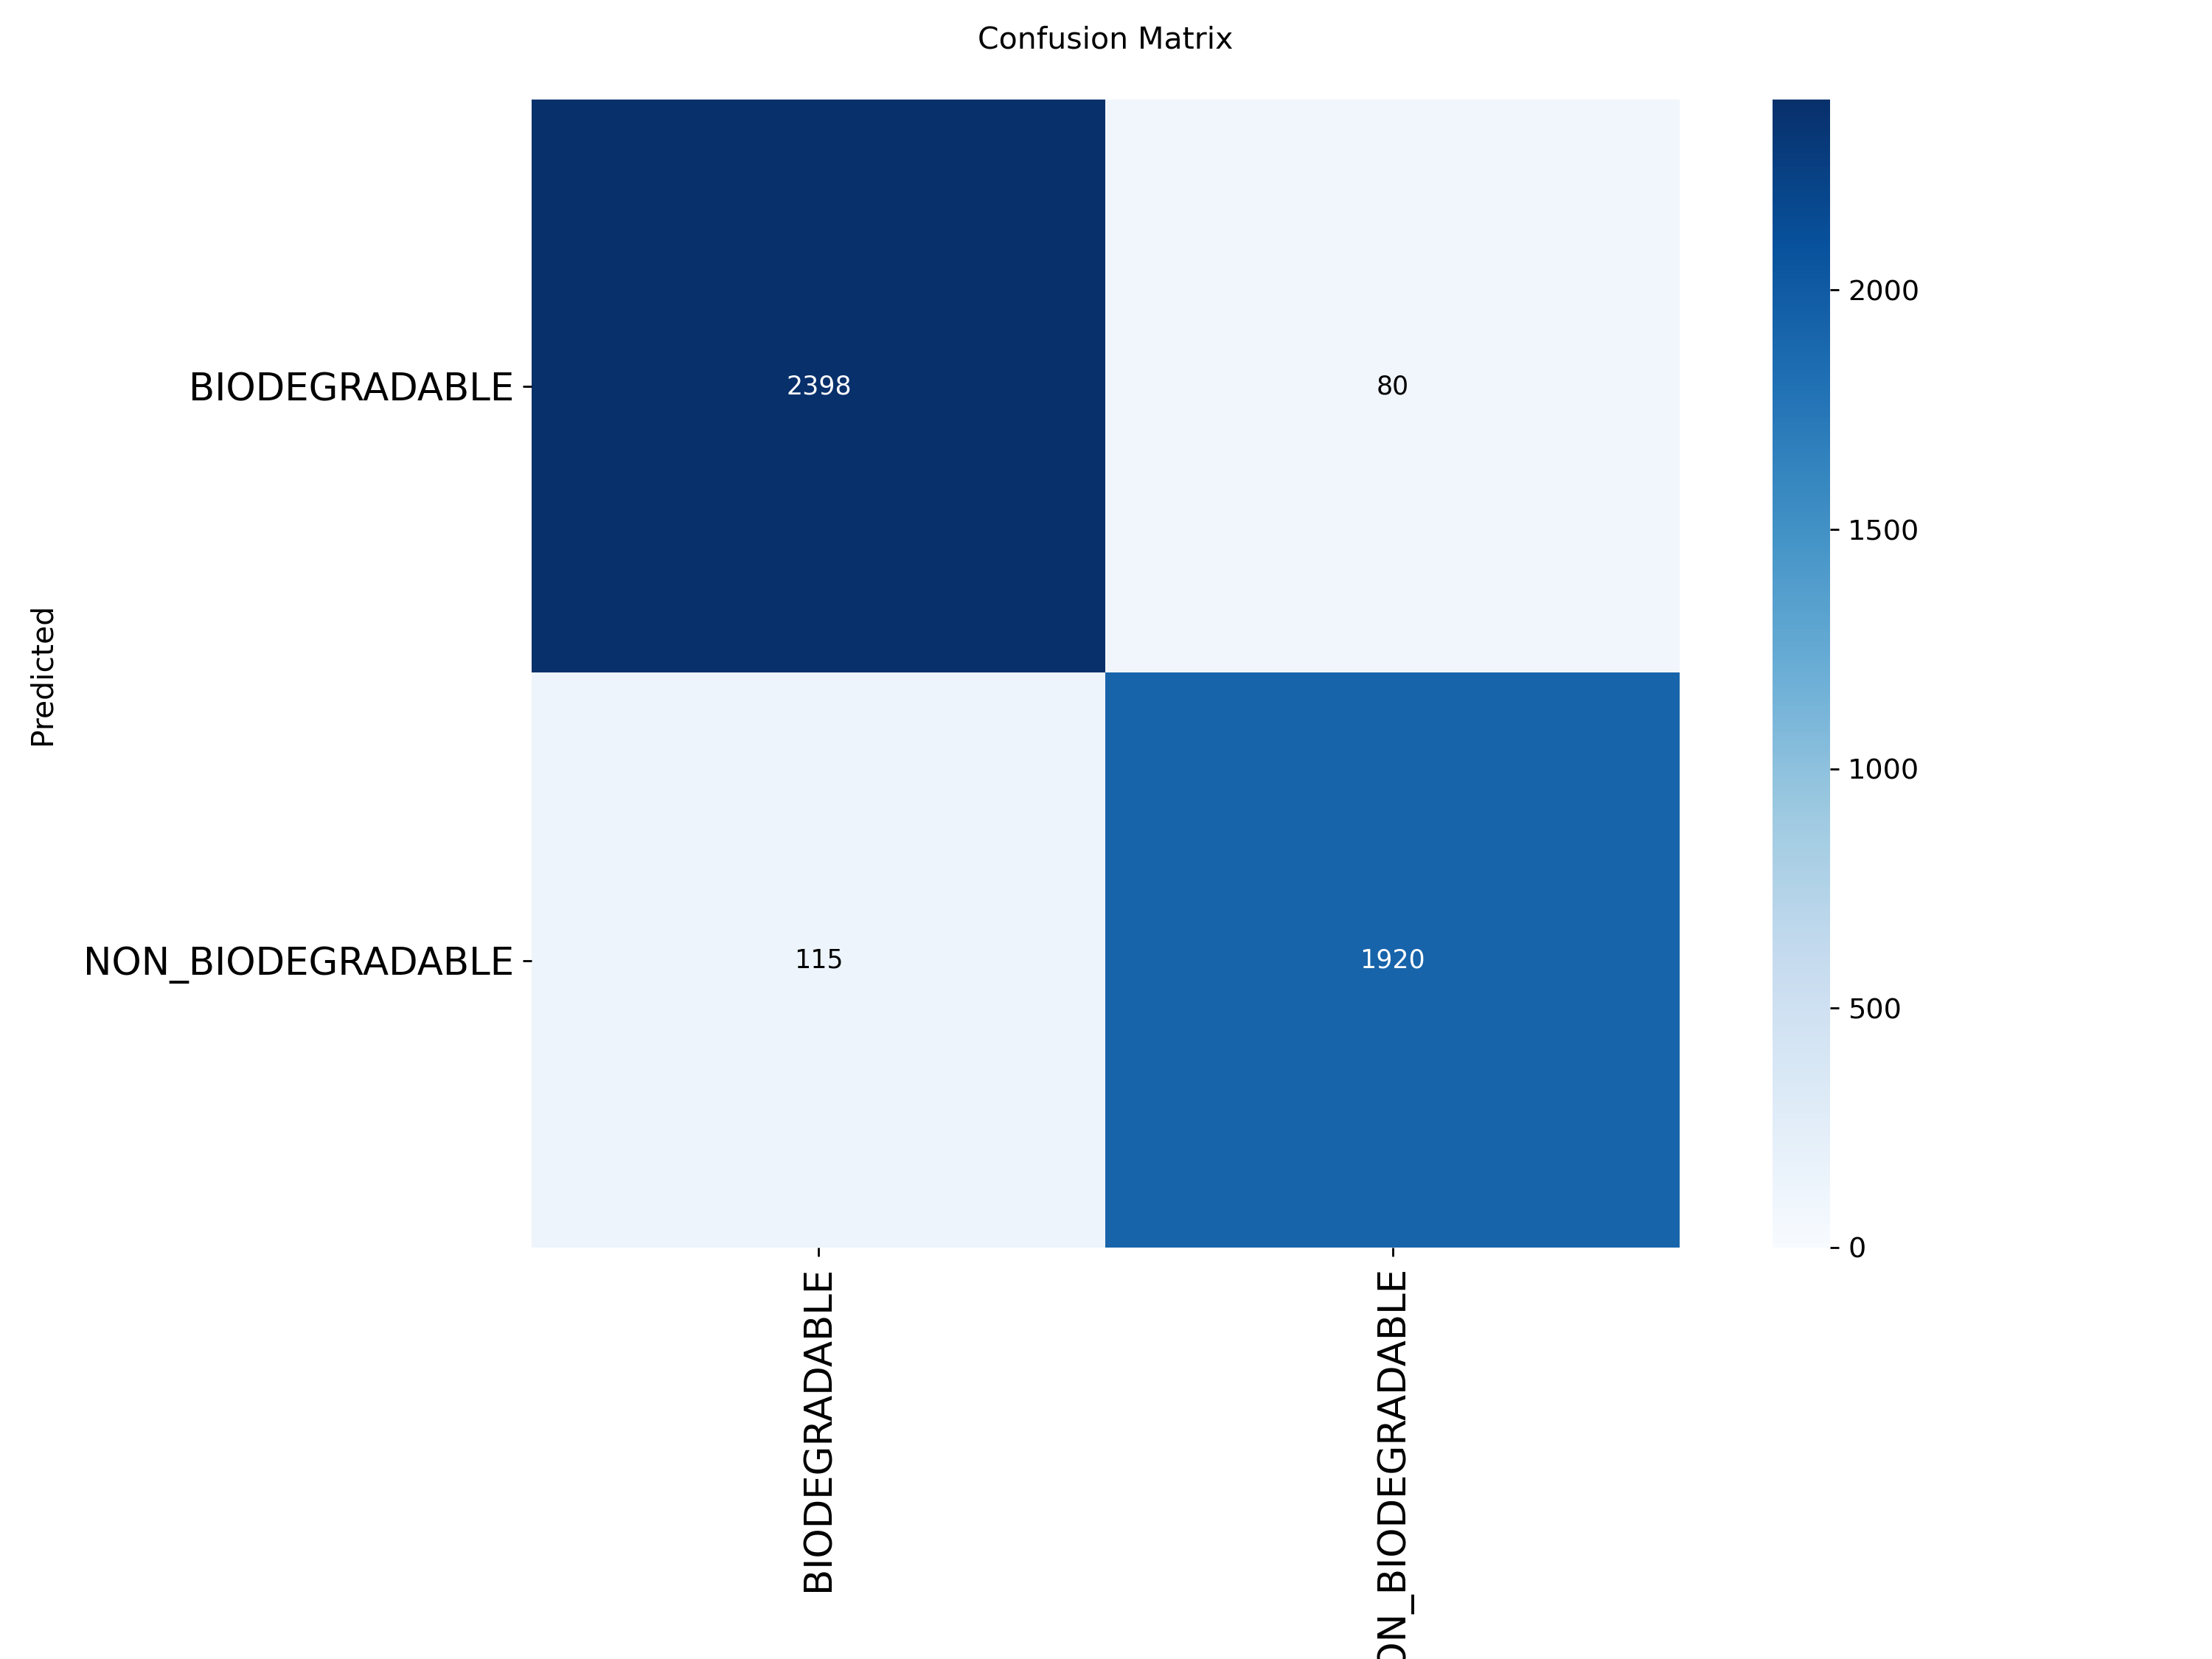

In [36]:
from IPython.display import Image, display

display(
    Image(
        filename="/content/waste_yolo/yolov8n_classification/confusion_matrix.png"
    )
)

In [37]:
img = test_images[0]

result = best_model.predict(
    source=img,
    save=True
)[0]

class_id = result.probs.top1
confidence = float(result.probs.top1conf)
class_name = result.names[class_id]

print("Prediction:", class_name)
print("Confidence:", f"{confidence*100:.2f}%")


image 1/1 /content/yolo_waste/test/NON_BIODEGRADABLE/R_10222.jpg: 224x224 BIODEGRADABLE 0.96, NON_BIODEGRADABLE 0.04, 3.6ms
Speed: 2.9ms preprocess, 3.6ms inference, 0.1ms postprocess per image at shape (1, 3, 224, 224)
Results saved to /content/runs/classify/predict
Prediction: BIODEGRADABLE
Confidence: 96.36%


In [38]:
from google.colab import files

uploaded = files.upload()

Saving biodegradable.jpg to biodegradable.jpg


In [39]:
uploaded_file = list(uploaded.keys())[0]

result = best_model.predict(
    source=uploaded_file,
    verbose=False
)[0]

class_id = result.probs.top1
confidence = float(result.probs.top1conf)

class_name = result.names[class_id]

print("\n==============================")
print("      WASTE CLASSIFICATION")
print("==============================")

print("Prediction :", class_name)
print("Confidence :", f"{confidence * 100:.2f}%")

if class_name == "BIODEGRADABLE":
    print("\nFINAL RESULT: BIODEGRADABLE")
else:
    print("\nFINAL RESULT: NON-BIODEGRADABLE")


      WASTE CLASSIFICATION
Prediction : BIODEGRADABLE
Confidence : 100.00%

FINAL RESULT: BIODEGRADABLE


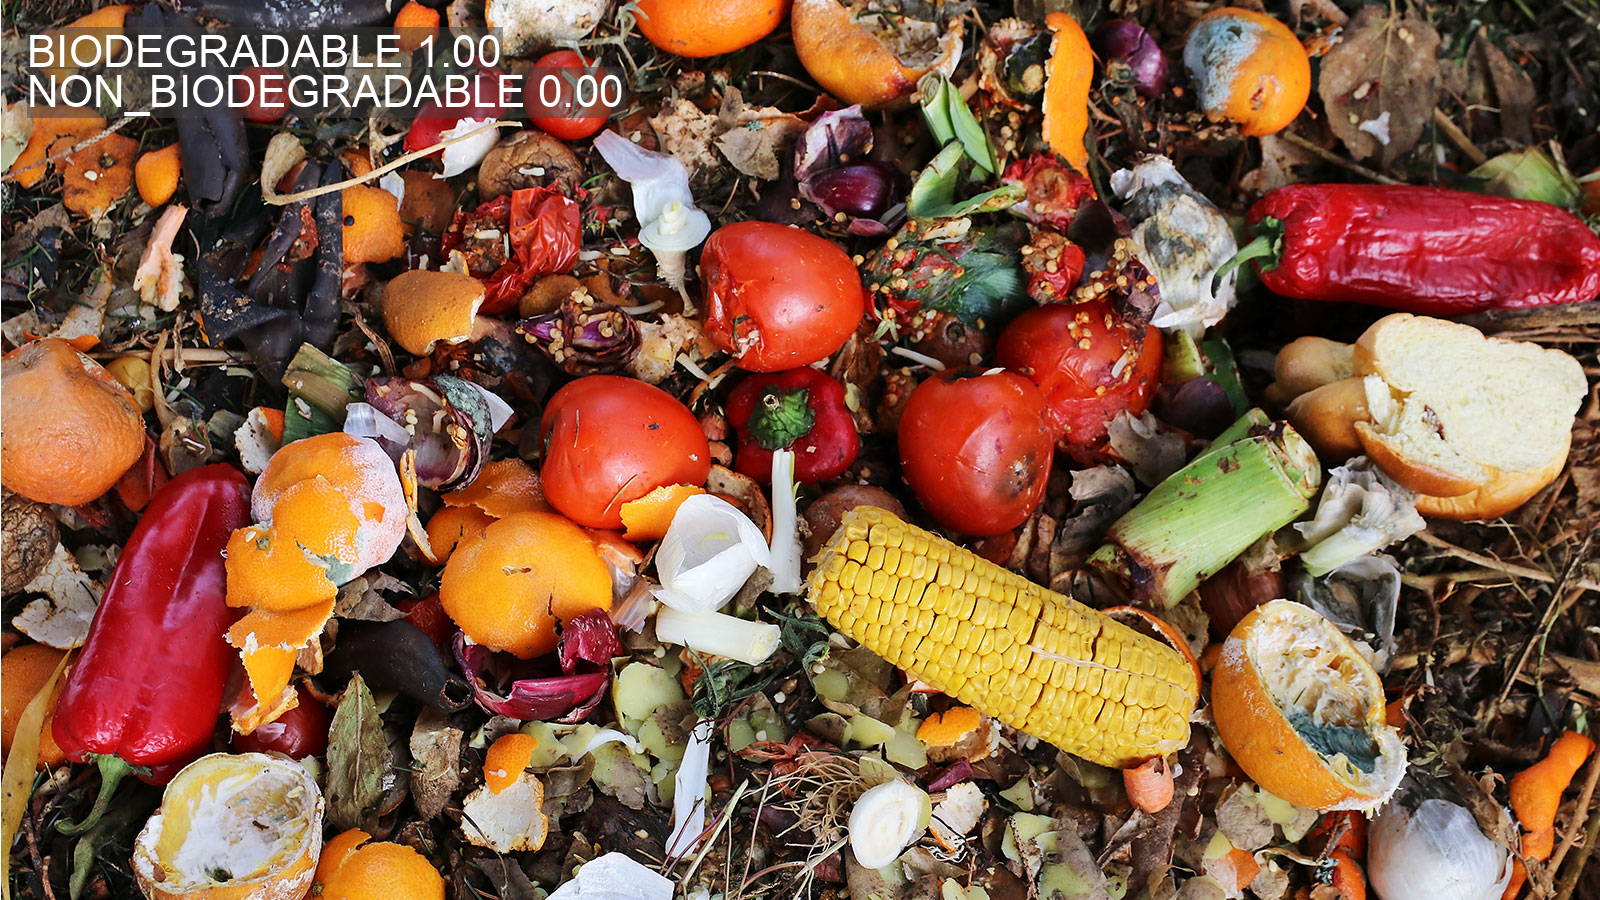

In [40]:
result.show()

In [41]:
from google.colab import files

uploaded = files.upload()

Saving non_biodegradable.jpg to non_biodegradable.jpg


In [42]:
uploaded_file = list(uploaded.keys())[0]

result = best_model.predict(
    source=uploaded_file,
    verbose=False
)[0]

class_id = result.probs.top1
confidence = float(result.probs.top1conf)

class_name = result.names[class_id]

print("\n==============================")
print("      WASTE CLASSIFICATION")
print("==============================")

print("Prediction :", class_name)
print("Confidence :", f"{confidence * 100:.2f}%")

if class_name == "BIODEGRADABLE":
    print("\nFINAL RESULT: BIODEGRADABLE")
else:
    print("\nFINAL RESULT: NON-BIODEGRADABLE")


      WASTE CLASSIFICATION
Prediction : NON_BIODEGRADABLE
Confidence : 99.86%

FINAL RESULT: NON-BIODEGRADABLE


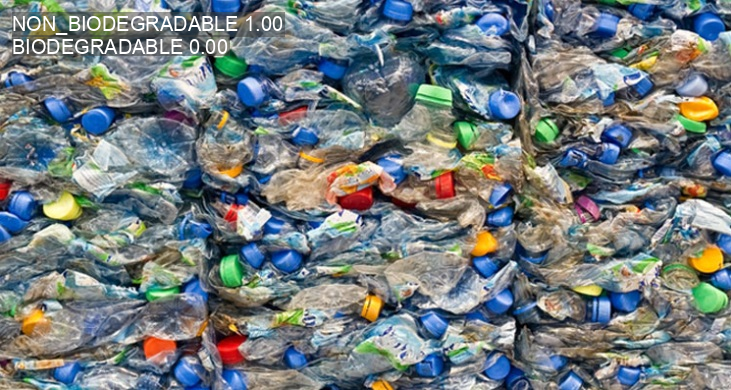

In [43]:
result.show()

In [44]:
print(
    f"Top-1 Accuracy: {metrics.top1 * 100:.2f}%"
)

Top-1 Accuracy: 95.68%


In [45]:
print(
    f"Top-5 Accuracy: {metrics.top5 * 100:.2f}%"
)

Top-5 Accuracy: 100.00%


In [46]:
import glob

best_files = glob.glob("/content/**/best.pt", recursive=True)

print("Found:")
for file in best_files:
    print(file)

Found:
/content/waste_yolo/yolov8n_classification/weights/best.pt


In [47]:
from google.colab import files

files.download(best_files[0])

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>